In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [7]:
df = pd.read_csv('Housing.csv')

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [8]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape:
(545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingst

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [9]:
print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [10]:
print("Total Duplicate Rows:")

print(df.duplicated().sum())

Total Duplicate Rows:
0


In [11]:
print("Minimum House Price:", df['price'].min())

print("Maximum House Price:", df['price'].max())

print("Average House Price:", df['price'].mean())

print("Median House Price:", df['price'].median())

Minimum House Price: 1750000
Maximum House Price: 13300000
Average House Price: 4766729.247706422
Median House Price: 4340000.0


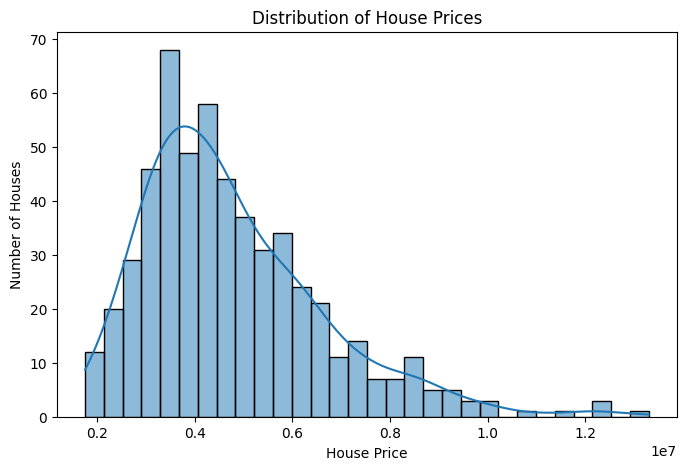

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.show()

In [13]:
median_price = df['price'].median()

df['price_category'] = (df['price'] > median_price).astype(int)

print("Median House Price:", median_price)

df[['price', 'price_category']].head(10)

Median House Price: 4340000.0


,price,price_category
0,13300000,1
1,12250000,1
2,12250000,1
3,12215000,1
4,11410000,1
5,10850000,1
6,10150000,1
7,10150000,1
8,9870000,1
9,9800000,1


In [14]:
df['price_label'] = df['price_category'].map({
    0: 'Low Price',
    1: 'High Price'
})

df[['price', 'price_category', 'price_label']].head(10)

,price,price_category,price_label
0,13300000,1,High Price
1,12250000,1,High Price
2,12250000,1,High Price
3,12215000,1,High Price
4,11410000,1,High Price
5,10850000,1,High Price
6,10150000,1,High Price
7,10150000,1,High Price
8,9870000,1,High Price
9,9800000,1,High Price


In [15]:
print("House Price Category Count:")
print(df['price_label'].value_counts())

House Price Category Count:
price_label
Low Price     275
High Price    270
Name: count, dtype: int64


In [16]:
print("House Price Category Percentage:")
print(df['price_label'].value_counts(normalize=True) * 100)

House Price Category Percentage:
price_label
Low Price     50.458716
High Price    49.541284
Name: proportion, dtype: float64


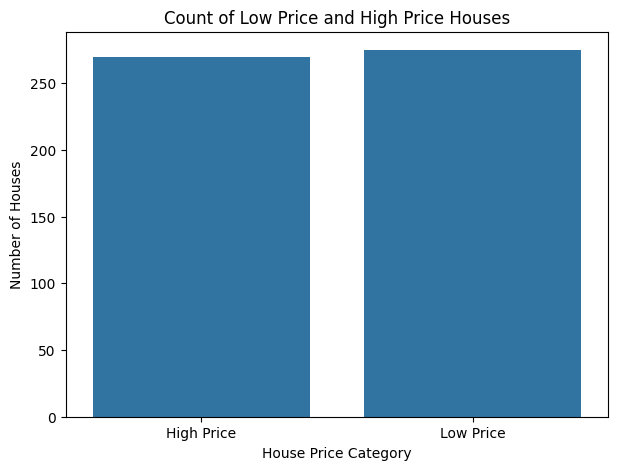

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='price_label')

plt.title("Count of Low Price and High Price Houses")
plt.xlabel("House Price Category")
plt.ylabel("Number of Houses")

plt.show()

In [18]:
# Target variable
y = df['price_category']

# Independent variables
X = df.drop(
    columns=['price', 'price_category', 'price_label'],
    errors='ignore'
)

print("Independent Variables (X):")
display(X.head())

print("Dependent Variable (y):")
display(y.head())

Independent Variables (X):


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Dependent Variable (y):


,price_category
0,1
1,1
2,1
3,1
4,1


In [19]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (545, 12)
Shape of y: (545,)


In [20]:
# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded Dataset:")
display(X.head())

Encoded Dataset:


,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,7420,4,1,2,2,1,1,1,0,1,0,0,0


In [21]:
print("Updated X Shape:", X.shape)

print("\nUpdated Column Names:")
print(X.columns.tolist())

print("\nData Types:")
print(X.dtypes)

Updated X Shape: (545, 13)

Updated Column Names:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

Data Types:
area                               int64
bedrooms                           int64
bathrooms                          int64
stories                            int64
parking                            int64
mainroad_yes                       int64
guestroom_yes                      int64
basement_yes                       int64
hotwaterheating_yes                int64
airconditioning_yes                int64
prefarea_yes                       int64
furnishingstatus_semi-furnished    int64
furnishingstatus_unfurnished       int64
dtype: object


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (436, 13)
Testing Data Shape: (109, 13)
Training Target Shape: (436,)
Testing Target Shape: (109,)


In [23]:
# Create StandardScaler object
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

print("\nTesting data after scaling:")
print(X_test_scaled[:5])

Training data after scaling:
[[-0.52498929 -1.29403923 -0.57124209 -0.90692803 -0.82788326  0.38780895
  -0.45946829 -0.7205302  -0.23598744 -0.68050514 -0.54200419 -0.85449326
   1.43889629]
 [-0.59681537 -1.29403923 -0.57124209 -0.90692803 -0.82788326  0.38780895
  -0.45946829 -0.7205302  -0.23598744 -0.68050514 -0.54200419  1.17028425
  -0.69497712]
 [-0.71652549 -1.29403923 -0.57124209 -0.90692803 -0.82788326  0.38780895
  -0.45946829 -0.7205302  -0.23598744 -0.68050514 -0.54200419 -0.85449326
   1.43889629]
 [-0.71652549  0.05896102 -0.57124209  0.22608235  0.33649449 -2.57858931
  -0.45946829 -0.7205302  -0.23598744 -0.68050514 -0.54200419 -0.85449326
   1.43889629]
 [-0.50583568 -1.29403923 -0.57124209 -0.90692803 -0.82788326  0.38780895
  -0.45946829 -0.7205302  -0.23598744 -0.68050514 -0.54200419 -0.85449326
   1.43889629]]

Testing data after scaling:
[[ 1.46219875  0.05896102  1.40543688 -0.90692803 -0.82788326  0.38780895
   2.17642875  1.38786689 -0.23598744 -0.68050514 -0

In [24]:
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (436, 13)
Scaled Testing Shape: (109, 13)


In [25]:
# Create Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [26]:
print("Model Coefficients:")
print(model.coef_)

print("\nModel Intercept:")
print(model.intercept_)

Model Coefficients:
[[ 0.94939081  0.21597172  0.52346357  0.85339175  0.12491718  0.42526702
   0.33534374  0.38368163  0.04174796  0.68735981  0.57148072  0.23628088
  -0.34000034]]

Model Intercept:
[0.12269691]


In [27]:
# Predict using testing data
y_pred = model.predict(X_test_scaled)

print("Predicted Values:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test.values[:20])

Predicted Values:
[1 1 0 0 0 1 0 0 0 0 0 0 0 1 1 0 1 1 1 0]

Actual Values:
[1 1 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 1 1]


In [28]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results['Actual Label'] = results['Actual'].map({
    0: 'Low Price',
    1: 'High Price'
})

results['Predicted Label'] = results['Predicted'].map({
    0: 'Low Price',
    1: 'High Price'
})

display(results.head(20))

,Actual,Predicted,Actual Label,Predicted Label
0,1,1,High Price,High Price
1,1,1,High Price,High Price
2,0,0,Low Price,Low Price
3,1,0,High Price,Low Price
4,0,0,Low Price,Low Price
5,1,1,High Price,High Price
6,0,0,Low Price,Low Price
7,0,0,Low Price,Low Price
8,1,0,High Price,Low Price
9,0,0,Low Price,Low Price


In [29]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Model Accuracy:", accuracy * 100, "%")

Logistic Regression Model Accuracy: 83.4862385321101 %


In [30]:
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Precision: 0.8333333333333334
Recall: 0.8333333333333334
F1 Score: 0.8333333333333334


In [31]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Low Price', 'High Price']
))

Classification Report:
              precision    recall  f1-score   support

   Low Price       0.84      0.84      0.84        55
  High Price       0.83      0.83      0.83        54

    accuracy                           0.83       109
   macro avg       0.83      0.83      0.83       109
weighted avg       0.83      0.83      0.83       109



In [32]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[46  9]
 [ 9 45]]


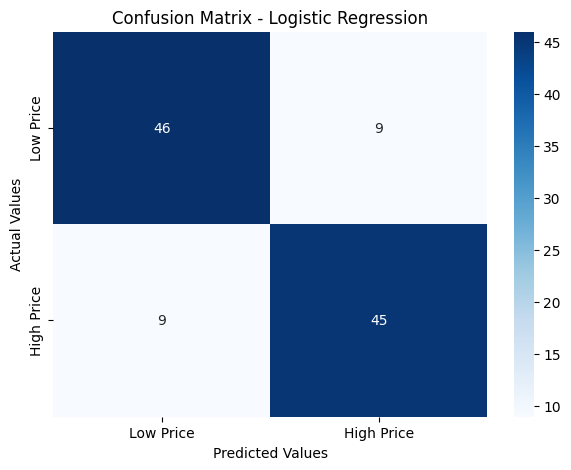

In [33]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Price', 'High Price'],
    yticklabels=['Low Price', 'High Price']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [34]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison['Actual'] = comparison['Actual'].map({
    0: 'Low Price',
    1: 'High Price'
})

comparison['Predicted'] = comparison['Predicted'].map({
    0: 'Low Price',
    1: 'High Price'
})

comparison.head(20)

,Actual,Predicted
0,High Price,High Price
1,High Price,High Price
2,Low Price,Low Price
3,High Price,Low Price
4,Low Price,Low Price
5,High Price,High Price
6,Low Price,Low Price
7,Low Price,Low Price
8,High Price,Low Price
9,Low Price,Low Price


<Figure size 1200x500 with 0 Axes>

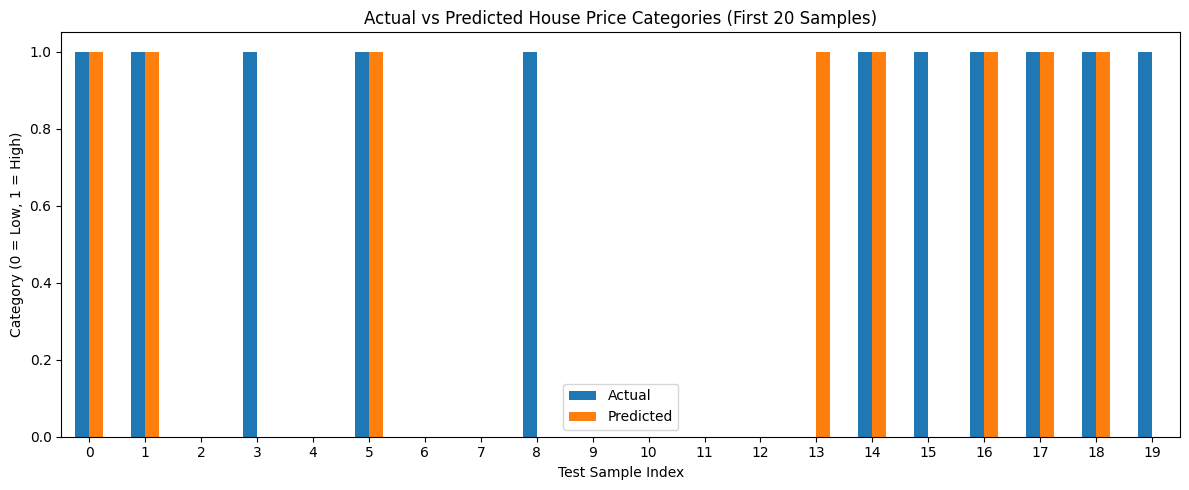

In [37]:
plt.figure(figsize=(12, 5))

# Plot the numeric columns from results
results[['Actual', 'Predicted']].head(20).plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title("Actual vs Predicted House Price Categories (First 20 Samples)")
plt.xlabel("Test Sample Index")
plt.ylabel("Category (0 = Low, 1 = High)")
plt.xticks(rotation=0)
plt.legend(['Actual', 'Predicted'])
plt.tight_layout()
plt.show()

In [38]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [39]:
# Save trained Logistic Regression model
joblib.dump(model, 'housing_logistic_model.pkl')

# Save the StandardScaler
joblib.dump(scaler, 'housing_scaler.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [44]:
from google.colab import files

files.download('housing_logistic_model.pkl')
files.download('housing_scaler.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>